# Lab 6: Odometry, model vs real robot

The robot drives the digit **32**. A second thread computes its odometry (formulas in the README) and logs `x,y,time` (m, m, ms since start). The same program ran in the TRIK Studio simulator (`odometry_data_sim_32.txt`) and on the real robot (`odometry_data_real_32.txt`).

The notebook shows two things: both trajectories on one plot, and the distance between them over time.

In [1]:
from google.colab import files
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

x_s, y_s, t_s = np.loadtxt('odometry_data_sim_32.txt', delimiter=',', unpack=True)
x_r, y_r, t_r = np.loadtxt('odometry_data_real_32.txt', delimiter=',', unpack=True)

Saving odometry_data_real_32.txt to odometry_data_real_32.txt
Saving odometry_data_sim_32.txt to odometry_data_sim_32.txt


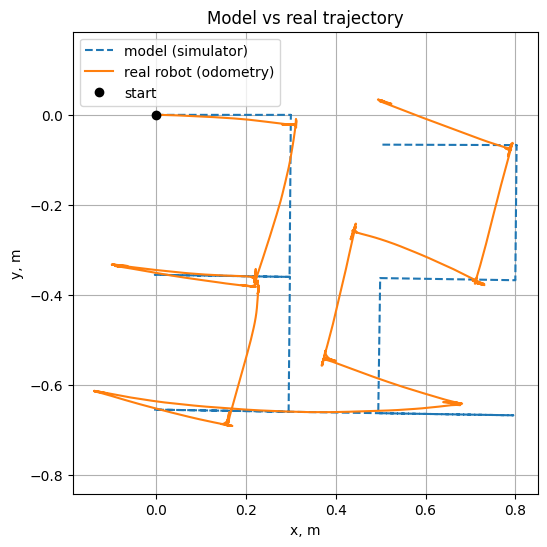

In [2]:
# 1. Trajectories on one plot
plt.figure(figsize=(6, 6))
plt.plot(x_s, y_s, '--', label='model (simulator)')
plt.plot(x_r, y_r,       label='real robot (odometry)')
plt.plot(0, 0, 'ko', label='start')
plt.axis('equal'); plt.grid(True); plt.legend()
plt.xlabel('x, m'); plt.ylabel('y, m')
plt.title('Model vs real trajectory')
plt.show()

**What the trajectory plot shows.** Both runs draw the 32 and end about 10 cm apart: the simulator at (0.50, -0.07) m, the real robot at (0.50, 0.03) m. In the simulator every line is straight and every corner is 90°. On the real robot the straight moves come out tilted, and the robot turns back at the end of each move.

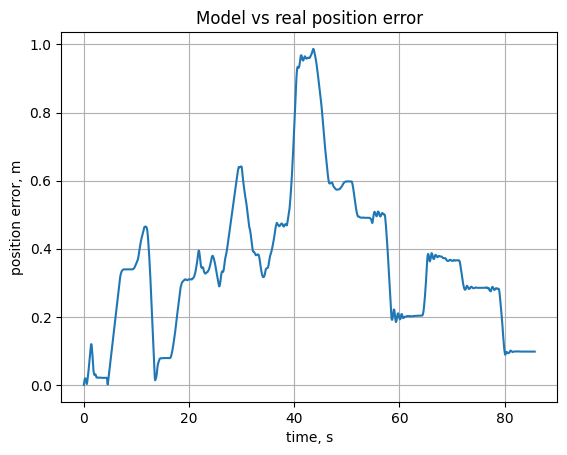

Final odometry error (sim vs real): 0.1 m
Max error: 1.0 m


In [3]:
# 2. Error over time (simulator resampled onto the real-robot timestamps)
t_s, t_r = t_s - t_s[0], t_r - t_r[0]
xs_i = np.interp(t_r, t_s, x_s)
ys_i = np.interp(t_r, t_s, y_s)
err = np.hypot(x_r - xs_i, y_r - ys_i)

plt.plot(t_r / 1000, err)
plt.xlabel('time, s'); plt.ylabel('position error, m'); plt.grid(True)
plt.title('Model vs real position error')
plt.show()

print(f'Final odometry error (sim vs real): {err[-1]:.1f} m')
print(f'Max error: {err.max():.1f} m')


**What it shows.** The final error is 0.1 m, but the error reaches 1.0 m around 44 s. The real run is slower (86 s against 51 s in the simulator), so at the same moment the two robots are at different parts of the 32. Most of this error comes from timing, not from a different path.